# Porter: Delivery Time Estimation using Neural Networks

**Section 5 of 5 (30 marks): Regression with Neural Networks**

| Section | Topic | Marks | File |
|:--:|:--|:--:|:--|
| 1 | Problem Statement, Data Import and Data Structure Analysis | 10 | [open](section_1_problem_and_data.ipynb) |
| 2 | Data Preprocessing and Feature Engineering | 30 | [open](section_2_preprocessing.ipynb) |
| 3 | Data Visualization, Outlier Detection and Cleaning | 20 | [open](section_3_visualization_outliers.ipynb) |
| 4 | Model Training with Random Forest | 10 | [open](section_4_random_forest.ipynb) |
| 5 | Regression with Neural Networks | 30 | **you are here** |

**Note.** This notebook continues from [section_4_random_forest.ipynb](section_4_random_forest.ipynb): it uses the data, variables and functions created in the earlier sections, and the outputs below were saved from one full run of the whole case study. To run the code again, run the cells in order from Section 1 (use `../solution.ipynb` to do this in one go).

<a id="sec5"></a>

# Section 5: Regression with Neural Networks (30 points)

### Objective and Tasks of this Section

**Stage 5 of 5 · 6 Tasks: Regression with Neural Networks**

**Objective:** You will scale the data, design and train a neural network regressor, check it for overfitting, and compare its performance directly against the random forest baseline.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 5.1** | Scale the feature data before feeding it into a neural network, and explain why scaling matters here but wasn't required for the random forest. | Think about how a neural network's gradient-based training reacts to features that are on very different numeric ranges, compared to how a tree-based model splits on raw values. |
| **Task 5.2** | Define a neural network architecture appropriate for this regression task, and justify your choice of activation functions. | Think about what activation the output layer needs for a continuous target, versus what activation is a strong general-purpose default for the hidden layers. |
| **Task 5.3** | Compile the model with an optimizer and loss function suited to this regression task, and briefly justify your choice of optimizer. | Think about the drawback of a fixed, single learning rate across all weights, and what an adaptive, per-parameter learning-rate optimizer offers instead. |
| **Task 5.4** | Train the network for a reasonable number of epochs, then plot training vs validation loss to check for overfitting. | Think about what it means for the validation loss to track closely with (or stay below) the training loss over the course of training. |
| **Task 5.5** | Evaluate the trained network on the test set using the same set of metrics used for the random forest, and directly compare the two models' results. | Think about why using the exact same metrics as your baseline is necessary in order to make a fair, direct comparison. |
| **Task 5.6** | Explain why neural networks tend to perform well as dataset size grows. | Think about the relationship between the number of learnable parameters in a network and the amount of data needed to estimate them reliably without overfitting. |

**Evaluation criteria of this section (30 points):**

| Criterion | Done in |
|:--|:--|
| Data scaling | 5.1 |
| Defining nn architecture | 5.2 |
| Trying different combinations and hyperparameters | 5.4 |
| Model training | 5.4 |
| Comparing results with random forest | 5.5 |

Each task below is marked in its heading, for example `(Task 5.1)`.

---


Now we build a neural network in PyTorch, following the structure used in the course: scale the data, build the model, choose the loss and the optimizer, write our own training loop, and try different configurations one at a time. At the end we compare the network with the Random Forest.

**Flow of this section:**

```
Scale --> Architecture --> Loss & optimizer --> Train & plot losses --> Try configurations --> Final model --> Compare with Random Forest
```

## 5.1 Scaling the Data (Task 5.1, Brief Question 7)

> **Brief Question 7:** *Why is scaling required for neural networks?*


Neural networks learn with gradient descent, so the size of the numbers matters. `subtotal` runs into thousands while `hour` is between 0 and 23. Unscaled inputs give a stretched, lopsided loss surface, and gradient descent zig-zags across it. A forest does not care, because it only compares each feature with a threshold.

**Standardisation** (`z = (x - mean) / std`) puts every column on the same footing. We fit the scaler on the **training set only** and just transform the other sets, otherwise information from data the model must never see would leak into training.

We also scale the **target**. A network starts with outputs near 0 while delivery times are around 46, so scaling `y` makes the first steps of training sensible. Predictions are converted back to minutes with `inverse_transform` before we calculate any metric.

To plot the training and validation loss we need a validation set. We set aside 12.5% of the training rows for it, so the network trains on 70% of the data, validates on 10%, and the test set (20%) stays untouched.

In [66]:
from sklearn.preprocessing import StandardScaler

X_train_nn, X_val, y_train_nn, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_nn)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train_nn.values.reshape(-1, 1))
y_val_s = y_scaler.transform(y_val.values.reshape(-1, 1))

y_std = y_scaler.scale_[0]
print("Train / validation / test rows:", len(X_train_nn), len(X_val), len(X_test))
print("Target mean and std used for scaling:", round(y_scaler.mean_[0], 2), round(y_std, 2))

Train / validation / test rows: 121039 17292 34583
Target mean and std used for scaling: 46.09 9.22


The box plots show the effect: on the left the raw columns live on completely different scales, on the right they are comparable.

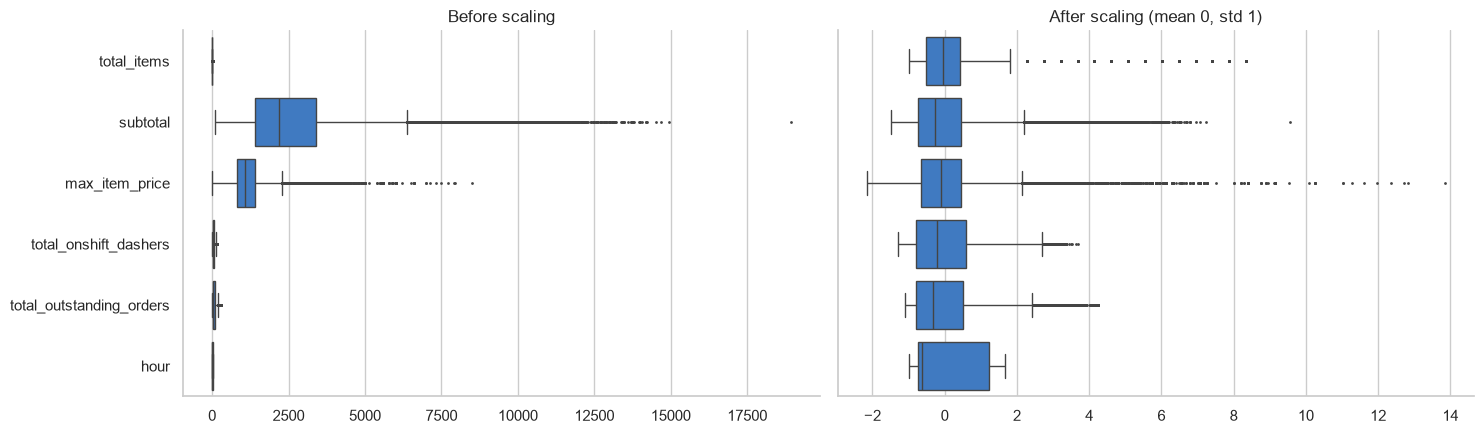

In [67]:
show_cols = ["total_items", "subtotal", "max_item_price", "total_onshift_dashers", "total_outstanding_orders", "hour"]
scaled_df = pd.DataFrame(X_train_s, columns=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=X_train_nn[show_cols], orient="h", color=BLUE, fliersize=1, ax=axes[0])
axes[0].set_title("Before scaling")
sns.boxplot(data=scaled_df[show_cols], orient="h", color=BLUE, fliersize=1, ax=axes[1])
axes[1].set_title("After scaling (mean 0, std 1)")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

PyTorch models work with tensors. Features become `float32`. The target is a column of shape `(N, 1)`, which is the shape of the model output. A `DataLoader` hands the model small shuffled batches. `seed_everything` fixes NumPy's and PyTorch's random numbers so that runs can be compared fairly.

In [68]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything()

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)

y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
y_val_t = torch.tensor(y_val_s, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)

xb, yb = next(iter(train_loader))
print("PyTorch", torch.__version__)
print("One batch -> features:", xb.shape, " targets:", yb.shape)

PyTorch 2.15.0
One batch -> features: torch.Size([256, 24])  targets: torch.Size([256, 1])


From the output above, the data is split into 121,039 training rows, 17,292 validation rows and 34,583 test rows. The scaler and the target scaler were fitted on the training rows only (target mean 46.09, standard deviation 9.22 minutes). One batch holds features of shape (256, 24) and targets of shape (256, 1), which is the shape of the model output.

## 5.2 Defining the Network Architecture and the Activation Functions (Task 5.2, Brief Question 9)

> **Brief Question 9:** *Which activation function did you use and why?*


The baseline network has two hidden layers:

| Layer | Description |
|:--|:--|
| Input | One neuron for each of the 24 input columns |
| Hidden 1 | 128 neurons with ReLU |
| Hidden 2 | 64 neurons with ReLU |
| Output | **1 neuron with no activation** |

**Which activation functions, and why?**

- **Hidden layers: ReLU**, `max(0, z)`. It is cheap, it keeps a gradient of exactly 1 for positive inputs so gradients do not vanish as they do with sigmoid and tanh, and it is the default in most modern networks. Its weakness is that a unit stuck at negative values stops learning (dying ReLU), which Leaky ReLU fixes. We test the alternatives in Section 5.4.
- **Output layer: linear (no activation).** The last neuron decides what the network predicts. A linear last neuron gives regression, and sigmoid or softmax would give classification. A sigmoid would squeeze the answer into 0 to 1, and a ReLU would cut off negative values, which the scaled target can take.

The chart compares the four activation functions we try, and their derivatives (the gradient signal that flows back during training).

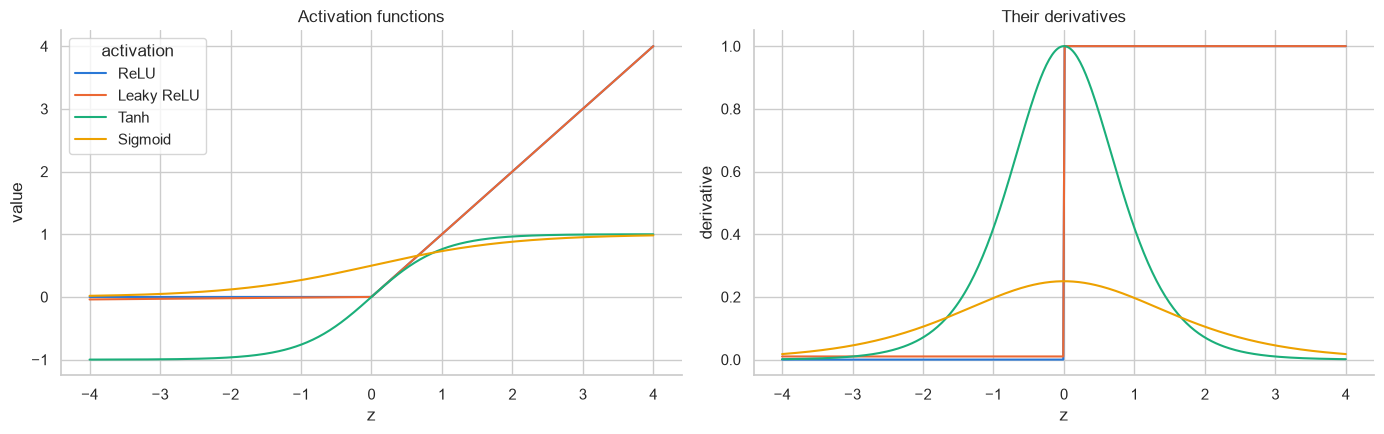

In [69]:
z = torch.linspace(-4, 4, 400, requires_grad=True)
activations = {"ReLU": torch.relu, "Leaky ReLU": lambda t: nn.functional.leaky_relu(t, 0.01), "Tanh": torch.tanh, "Sigmoid": torch.sigmoid}

curves = []
for name, f in activations.items():
    out = f(z)
    grad, = torch.autograd.grad(out.sum(), z)
    curves.append(pd.DataFrame({"z": z.detach().numpy(), "value": out.detach().numpy(), "derivative": grad.numpy(), "activation": name}))
curves = pd.concat(curves)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=curves, x="z", y="value", hue="activation", palette=[BLUE, ORANGE, AQUA, YELLOW], ax=axes[0])
axes[0].set_title("Activation functions")
sns.lineplot(data=curves, x="z", y="derivative", hue="activation", palette=[BLUE, ORANGE, AQUA, YELLOW], legend=False, ax=axes[1])
axes[1].set_title("Their derivatives")
plt.tight_layout()
plt.show()

`make_net` builds the network from a list of hidden sizes and an activation. As in the course, weights start with Xavier initialisation and biases at zero, and the last layer has **no** activation.

In [70]:
def make_net(hidden=(128, 64), act=nn.ReLU, dropout=0.0, bn=False):
    layers, d = [], X_train_t.shape[1]
    for w in hidden:
        layers.append(nn.Linear(d, w))
        if bn:
            layers.append(nn.BatchNorm1d(w))
        layers.append(act())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = w
    model = nn.Sequential(*layers, nn.Linear(d, 1))        # last layer: no activation
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

torch.manual_seed(0)
model = make_net()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=24, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 11521


From the output above, the network has 24 inputs, two ReLU hidden layers of 128 and 64 units, and one linear output neuron. That is 11,521 trainable parameters: 24 x 128 + 128 = 3,200, then 128 x 64 + 64 = 8,256, then 64 + 1 = 65.

## 5.3 Loss Function and Optimizer (Task 5.3, Brief Question 8)

> **Brief Question 8:** *Briefly explain your choice of optimizer.*


- **Loss: `nn.MSELoss()`**, the mean squared error. It is the standard loss for a continuous target, it is smooth, and it punishes big misses more than small ones. We report results as RMSE in minutes, which is easier to read.
- **Optimizer: Adam**, with learning rate 0.001 to start. Plain gradient descent uses one fixed learning rate for every weight and zig-zags on a lopsided loss surface. Momentum smooths the direction, RMSprop shrinks the step where gradients have been large, and **Adam combines both**, with a correction for its first steps. It is a strong default that needs little tuning. Adam still needs a learning rate, so we compare learning rates in Section 5.4.

In [71]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# one forward and backward pass on one batch, before any training
loss = criterion(model(xb), yb)
loss.backward()
print("Loss before training (scaled units):", round(loss.item(), 3))
print("Gradient shapes -> first layer:", tuple(model[0].weight.grad.shape), " last layer:", tuple(model[-1].weight.grad.shape))

Loss before training (scaled units): 1.167
Gradient shapes -> first layer: (128, 24)  last layer: (1, 64)


From the output above, the untrained network has a loss of 1.17 in scaled units. This is close to 1, as expected: an untrained network predicts values near 0 for a target that has been scaled to variance 1, and the random starting weights add a little more. The gradient shapes match the weight shapes ((128, 24) and (1, 64)), so backpropagation is connected properly.

## 5.4 Training the Network and Plotting the Losses (Task 5.4)

We write the training loop ourselves, as in the course. For every batch: `zero_grad`, forward pass, loss, `backward`, `step`. At the end of every epoch we switch to `model.eval()`, measure the error on the training and validation sets with `torch.no_grad()`, and record it in `h`. Errors are recorded as RMSE in minutes. After training, the function loads the weights of the epoch with the lowest validation error.

In [72]:
def fit(model, opt, epochs=40, bs=256):
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=bs, shuffle=True)
    h = {"train": [], "val": []}
    best, best_state = float("inf"), None
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); criterion(model(xb), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            h["train"].append(criterion(model(X_train_t), y_train_t).item() ** 0.5 * y_std)
            v = criterion(model(X_val_t), y_val_t).item()
            h["val"].append(v ** 0.5 * y_std)
        if v < best:
            best, best_state = v, {k: t.clone() for k, t in model.state_dict().items()}
    if best_state is not None:                       # stays None only if the loss became NaN (diverged)
        model.load_state_dict(best_state)
    h["best_epoch"] = int(np.nanargmin(h["val"])) if np.isfinite(h["val"]).any() else 0
    return h

def show(h, title=""):
    curves = pd.DataFrame({"epoch": range(1, len(h["train"]) + 1), "training": h["train"], "validation": h["val"]})
    curves = curves.melt(id_vars="epoch", var_name="set", value_name="RMSE (minutes)")
    plt.figure(figsize=(9, 4.5))
    sns.lineplot(data=curves, x="epoch", y="RMSE (minutes)", hue="set", palette=[BLUE, ORANGE])
    plt.axvline(h["best_epoch"] + 1, color="#52514e", linestyle=":", linewidth=1.5, label="best epoch")
    plt.title(title)
    plt.legend()
    plt.show()

Let's train the baseline for 60 epochs and plot the training and validation loss.

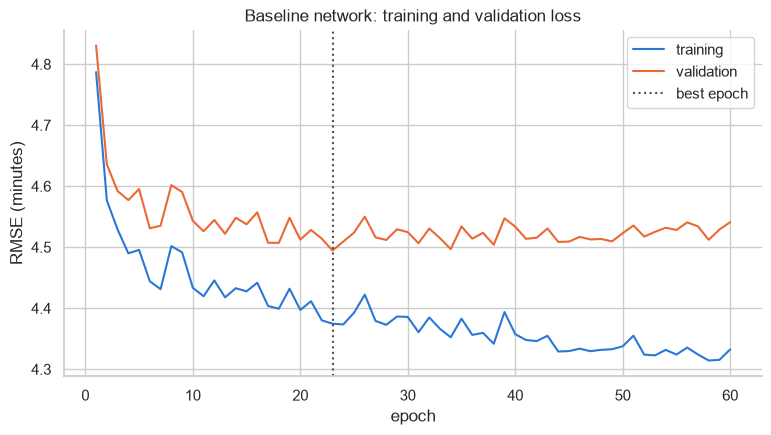

In [73]:
torch.manual_seed(0)
base = make_net()
h_base = fit(base, torch.optim.Adam(base.parameters(), lr=1e-3), epochs=60)
show(h_base, "Baseline network: training and validation loss")

In [74]:
print("Last epoch -> train RMSE", round(h_base["train"][-1], 3), "| validation RMSE", round(h_base["val"][-1], 3), "minutes")
print("Best epoch ->", h_base["best_epoch"] + 1, "with validation RMSE", round(h_base["val"][h_base["best_epoch"]], 3), "minutes")

Last epoch -> train RMSE 4.332 | validation RMSE 4.541 minutes
Best epoch -> 23 with validation RMSE 4.495 minutes


From the output and the chart, the baseline network reaches its best validation RMSE of 4.495 minutes at epoch 23. After that, the training RMSE keeps falling slowly (4.33 at epoch 60) while the validation RMSE stays near 4.5 (4.54 at epoch 60), so a gap of about 0.21 minutes opens up. This is mild overfitting, not a collapse: the validation loss does not climb steeply, and keeping the weights of the best epoch removes the problem.

### Trying Different Configurations

The brief also asks us to try different combinations and hyperparameters. This part belongs to Task 5.4: the network is trained several times, and we keep the best configuration.

We now follow the debugging method from the Practical Aspects class: **change one thing at a time** and keep a scoreboard. Every run starts from the same seed, so differences come from the change and not from luck. Each run trains for 40 epochs and keeps the weights of the best epoch. `run` records the training error, the last validation error, the best validation error and the best epoch.

In [75]:
results = {}
histories = {}
configs = {}

def make_optimizer(params, optimizer, lr, wd=0.0):
    if optimizer == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if optimizer == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    if optimizer == "sgd":
        return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)       # "sgd_momentum"

def run(name, group, hidden=(128, 64), act=nn.ReLU, optimizer="adam", lr=1e-3, bs=256, epochs=40, dropout=0.0, bn=False, wd=0.0):
    torch.manual_seed(0)
    m = make_net(hidden, act, dropout, bn)
    opt = make_optimizer(m.parameters(), optimizer, lr, wd)
    h = fit(m, opt, epochs=epochs, bs=bs)
    histories[name] = h
    configs[name] = dict(hidden=hidden, act=act, optimizer=optimizer, lr=lr, bs=bs, dropout=dropout, bn=bn, wd=wd)
    results[name] = [group, h["train"][-1], h["val"][-1], min(h["val"]), h["best_epoch"] + 1]

def scoreboard(group):
    table = pd.DataFrame(results, index=["group", "train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]).T
    table = table[table["group"] == group].drop(columns="group")
    return table.astype(float).round(3)

def plot_group(group, title):
    table = scoreboard(group).sort_values("best_val_RMSE")
    plt.figure(figsize=(9, 0.6 * len(table) + 1.5))
    ax = sns.barplot(x=table["best_val_RMSE"], y=table.index, color=BLUE)
    ax.bar_label(ax.containers[0], fmt="%.3f", fontsize=9)
    plt.title(title)
    plt.xlabel("best validation RMSE (minutes)")
    plt.ylabel("")
    plt.show()

def plot_curves(names, title, palette):
    long = pd.concat([pd.DataFrame({"epoch": range(1, len(histories[n]["val"]) + 1), "validation RMSE": histories[n]["val"], "run": n}) for n in names])
    plt.figure(figsize=(9, 4.5))
    sns.lineplot(data=long, x="epoch", y="validation RMSE", hue="run", palette=palette, linewidth=2)
    plt.title(title)
    plt.show()

#### Experiment 1: Size of the Network

Wider and deeper networks can learn more, but also need more data and time.

In [76]:
for hidden in [(32,), (64, 32), (128, 64), (256, 128, 64), (128, 64, 32, 16)]:
    run(f"size {hidden}", "size", hidden=hidden)

scoreboard("size")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
"size (32,)",4.440,4.491,4.482,35.0
"size (64, 32)",4.398,4.493,4.493,25.0
"size (128, 64)",4.357,4.534,4.495,23.0
"size (256, 128, 64)",4.192,4.566,4.513,17.0
"size (128, 64, 32, 16)",4.333,4.536,4.511,27.0


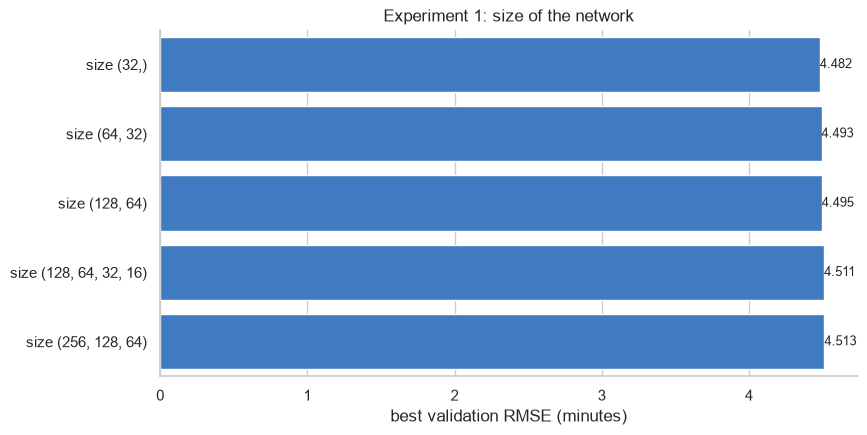

In [77]:
plot_group("size", "Experiment 1: size of the network")

From the scoreboard, all five sizes finish within 0.04 minutes of each other (best validation RMSE 4.482 to 4.513). The smallest network, one hidden layer of 32 units, is the best. The largest, (256, 128, 64), has the lowest training error (4.192) but the highest validation error at its last epoch (4.566), a sign of overfitting. More capacity did not help here.

#### Experiment 2: Activation Function

Same network, only the hidden activation changes.

In [78]:
for name, act in [("ReLU", nn.ReLU), ("Leaky ReLU", nn.LeakyReLU), ("Tanh", nn.Tanh), ("Sigmoid", nn.Sigmoid)]:
    run(f"activation {name}", "activation", act=act)

scoreboard("activation")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
activation ReLU,4.357,4.534,4.495,23.0
activation Leaky ReLU,4.362,4.533,4.494,23.0
activation Tanh,4.416,4.525,4.497,34.0
activation Sigmoid,4.442,4.495,4.490,38.0


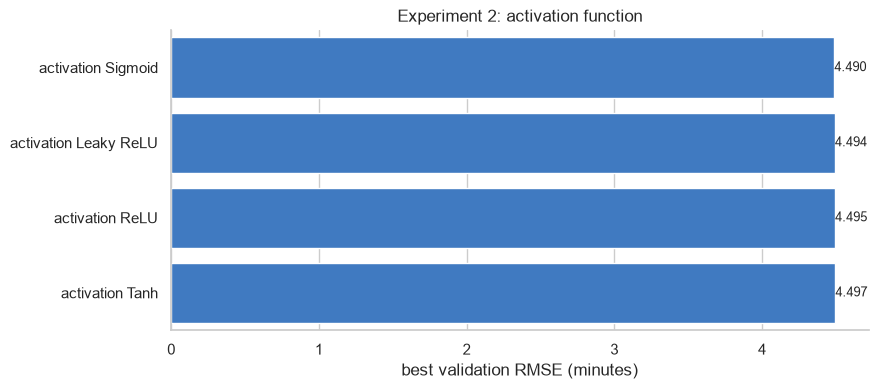

In [79]:
plot_group("activation", "Experiment 2: activation function")

From the scoreboard, the four activations are within 0.007 minutes of each other (4.490 to 4.497). ReLU and Leaky ReLU reach their best epoch at epoch 23, Tanh at epoch 34 and Sigmoid at epoch 38, so Sigmoid trains the most slowly. The gaps are too small to call a winner from one run each, so we keep ReLU for the reasons given in Section 5.2.

#### Experiment 3: The Optimiser Race

The same network with four optimisers, as in the SwiftLend case: plain SGD (learning rate 0.01), SGD with momentum (learning rate 0.001), RMSprop (0.001) and Adam (0.001). Momentum makes the effective step larger. We first tried it with a learning rate of 0.01, and on this target the training diverged (the loss became NaN), so we use 0.001.

In [80]:
run("optimiser SGD", "optimiser", optimizer="sgd", lr=0.01)
run("optimiser SGD + Momentum", "optimiser", optimizer="sgd_momentum", lr=1e-3)
run("optimiser RMSprop", "optimiser", optimizer="rmsprop", lr=1e-3)
run("optimiser Adam", "optimiser", optimizer="adam", lr=1e-3)

scoreboard("optimiser")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
optimiser SGD,4.469,4.550,4.540,39.0
optimiser SGD + Momentum,4.456,4.537,4.537,39.0
optimiser RMSprop,4.376,4.577,4.509,38.0
optimiser Adam,4.357,4.534,4.495,23.0


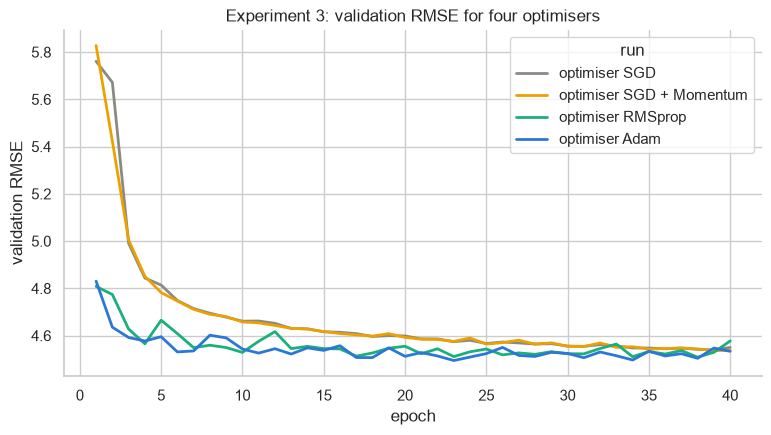

In [81]:
plot_curves(["optimiser SGD", "optimiser SGD + Momentum", "optimiser RMSprop", "optimiser Adam"],
            "Experiment 3: validation RMSE for four optimisers", [GRAY, YELLOW, AQUA, BLUE])

From the scoreboard, Adam (4.495) and RMSprop (4.509) beat plain SGD (4.540) and SGD with momentum (4.537), which were still improving at epoch 39 of 40 and would need more epochs or a larger learning rate. SGD with momentum at learning rate 0.01 did not train at all: the loss became NaN from the first epoch (we re-ran it for five epochs to confirm), which is why that run uses 0.001. This is the practical reason to choose Adam: it gives a good result quickly without careful tuning of the learning rate.

#### Experiment 4: Learning Rate

The learning rate is the first hyperparameter to tune. As in the Practical Aspects class we try values that differ by large factors, a log-scale spread, with Adam.

In [82]:
for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    run(f"learning rate {lr:g}", "learning rate", lr=lr)

scoreboard("learning rate")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
learning rate 0.0001,4.424,4.531,4.528,39.0
learning rate 0.0003,4.374,4.524,4.512,23.0
learning rate 0.001,4.357,4.534,4.495,23.0
learning rate 0.003,4.380,4.546,4.495,18.0
learning rate 0.01,4.440,4.516,4.497,34.0


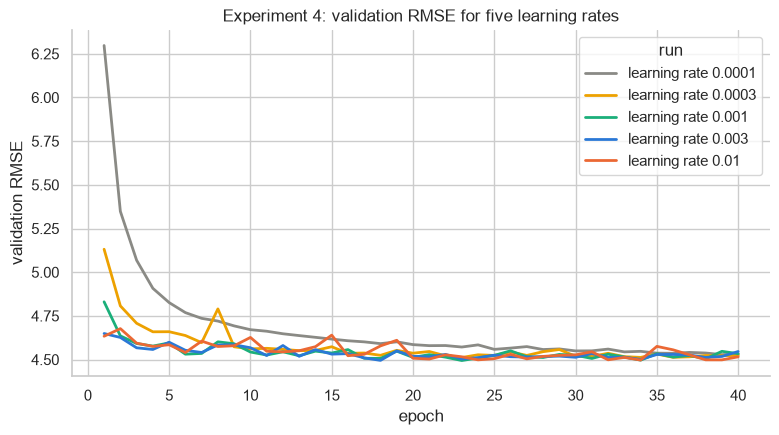

In [83]:
plot_curves([f"learning rate {lr:g}" for lr in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]],
            "Experiment 4: validation RMSE for five learning rates", [GRAY, YELLOW, AQUA, BLUE, ORANGE])

From the scoreboard, learning rates from 0.0003 to 0.01 all land between 4.495 and 4.512, and 0.001 and 0.003 tie for the best (4.495). Only 0.0001 is clearly slower (4.528, best epoch 39, still improving). A wide range works because Adam adapts the step for every weight and the inputs are standardised.

#### Experiment 5: Batch Size

A small batch updates the weights more often but with noisier gradients. A large batch gives smoother gradients and a faster epoch, but fewer updates.

In [84]:
for bs in [64, 128, 256, 512, 1024]:
    run(f"batch size {bs}", "batch size", bs=bs)

scoreboard("batch size")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
batch size 64,4.349,4.555,4.496,17.0
batch size 128,4.347,4.529,4.492,23.0
batch size 256,4.357,4.534,4.495,23.0
batch size 512,4.365,4.526,4.503,36.0
batch size 1024,4.378,4.523,4.497,35.0


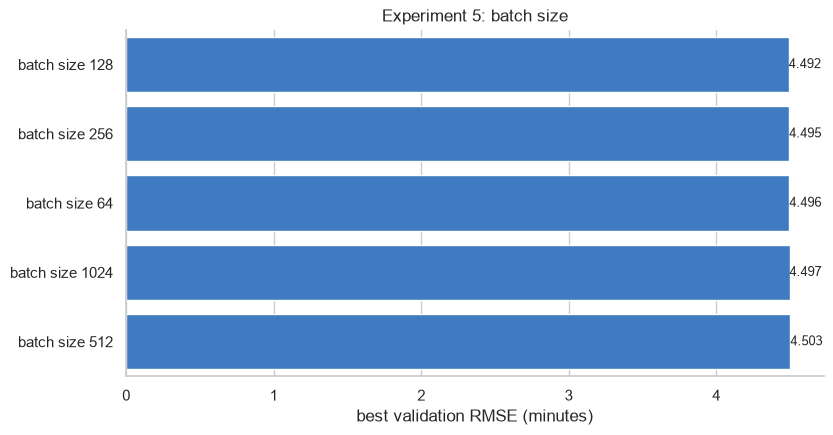

In [85]:
plot_group("batch size", "Experiment 5: batch size")

From the scoreboard, batch sizes from 64 to 1024 all finish between 4.492 and 4.503, so batch size hardly matters here. The two largest batches reach their best epoch later (epochs 36 and 35 for 512 and 1024, against epochs 17 to 23 for 64 to 256) because they make fewer weight updates per epoch.

#### Experiment 6: Regularisation

The baseline network showed a small gap between its training and validation error. Three standard remedies from the Hyperparameter Tuning class can shrink such a gap: **weight decay** (an L2 penalty that keeps the weights small, set with Adam's `weight_decay`), **dropout** (randomly switching off a share of the neurons while training, and off again when predicting) and **batch normalisation** (standardising the values inside the network). We apply them one at a time to the baseline network (128, 64).

In [86]:
run("regularisation weight decay 1e-4", "regularisation", wd=1e-4)
run("regularisation weight decay 1e-3", "regularisation", wd=1e-3)
run("regularisation dropout 0.1", "regularisation", dropout=0.1)
run("regularisation dropout 0.3", "regularisation", dropout=0.3)
run("regularisation batch norm", "regularisation", bn=True)

scoreboard("regularisation")

,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
regularisation weight decay 1e-4,4.384,4.516,4.488,34.0
regularisation weight decay 1e-3,4.446,4.515,4.487,34.0
regularisation dropout 0.1,4.391,4.490,4.488,36.0
regularisation dropout 0.3,4.421,4.485,4.485,40.0
regularisation batch norm,4.374,4.528,4.500,38.0


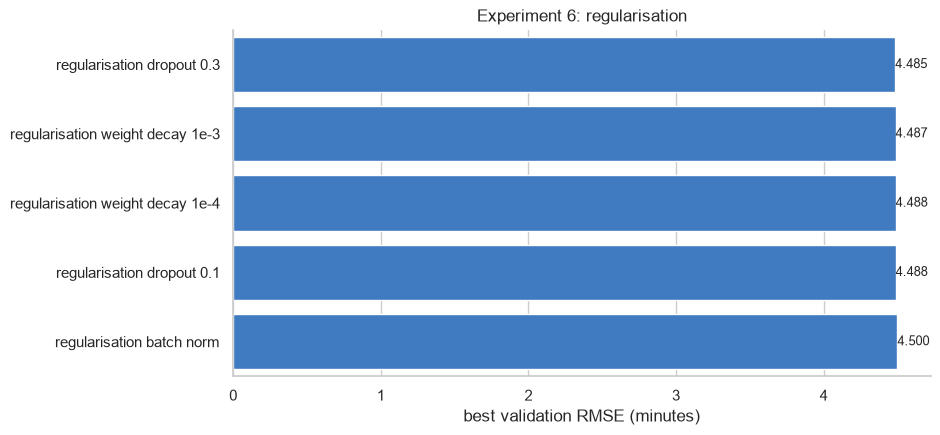

In [87]:
plot_group("regularisation", "Experiment 6: regularisation")

From the scoreboard, all five regularised networks land within 0.015 minutes of each other (4.485 to 4.500), against 4.495 for the same network without regularisation. Dropout 0.3 is the best of them (4.485) and it shrinks the gap between training and validation error at the last epoch from 0.18 to 0.06 minutes, so it does what it should, but the gain in validation error is only 0.010 minutes. Batch normalisation is slightly worse than no regularisation (4.500), as it also was in the SwiftLend case study. None of them beats the small 32-unit network (4.482): a small network is itself a form of regularisation.

#### The Full Scoreboard

Every run from the six experiments in one chart, coloured by experiment.

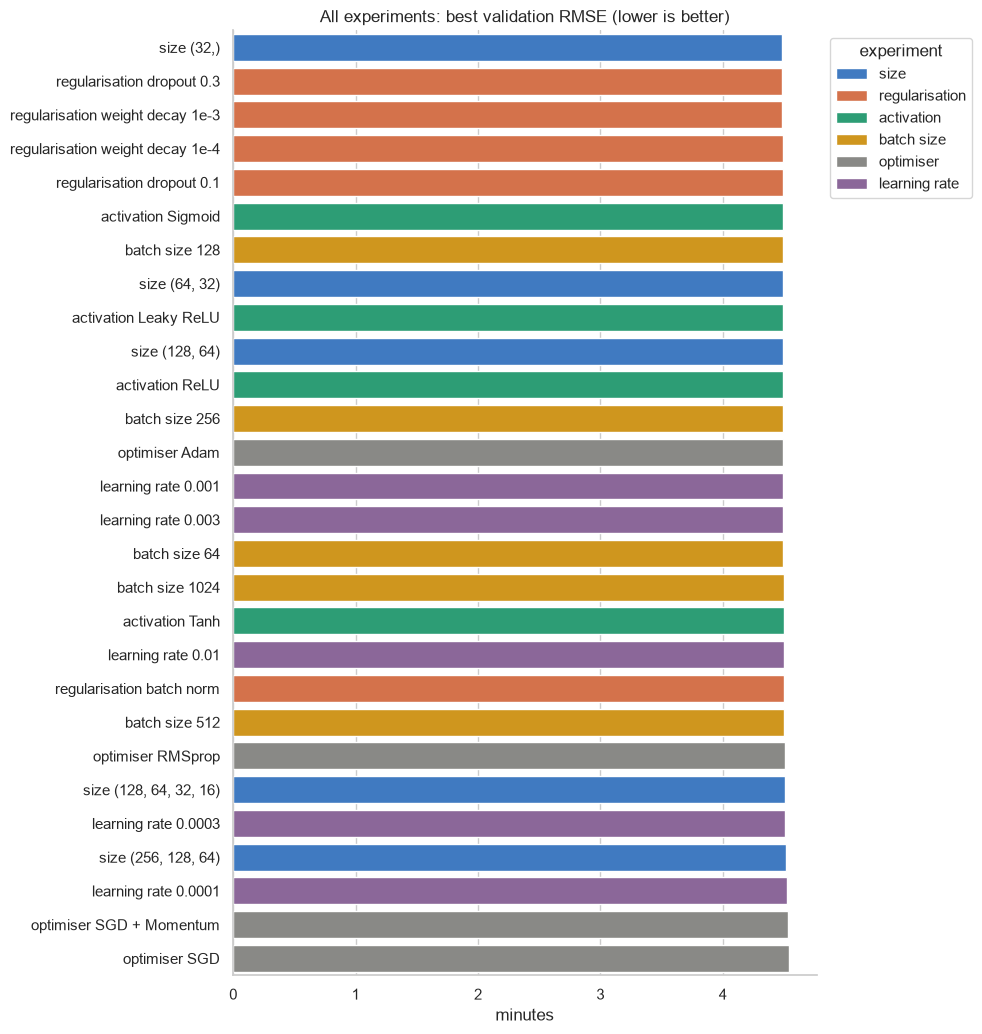

,group,train_RMSE,val_RMSE,best_val_RMSE,best_epoch
"size (32,)",size,4.440,4.491,4.482,35.0
regularisation dropout 0.3,regularisation,4.421,4.485,4.485,40.0
regularisation weight decay 1e-3,regularisation,4.446,4.515,4.487,34.0
regularisation weight decay 1e-4,regularisation,4.384,4.516,4.488,34.0
regularisation dropout 0.1,regularisation,4.391,4.490,4.488,36.0


In [88]:
board = pd.DataFrame(results, index=["group", "train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]).T
board[["train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]] = board[["train_RMSE", "val_RMSE", "best_val_RMSE", "best_epoch"]].astype(float)
board = board.sort_values("best_val_RMSE")

plt.figure(figsize=(10, 10.5))
sns.barplot(data=board, x="best_val_RMSE", y=board.index, hue="group", dodge=False,
            palette=[BLUE, ORANGE, AQUA, YELLOW, GRAY, "#8e5ea2"])
plt.title("All experiments: best validation RMSE (lower is better)")
plt.xlabel("minutes")
plt.ylabel("")
plt.legend(title="experiment", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

board.head(5).round(3)

From the chart, there are 28 runs (five of them are the same baseline configuration, counted once in each experiment). Their best validation RMSE runs from 4.482 to 4.540 minutes, a spread of 0.06 minutes (about 1.3%). The bars start at zero on purpose, so that the chart does not exaggerate the gaps: no single hyperparameter matters much for this problem, and the order of the top few runs should not be over-read. Choosing the best run by **validation** error is still the right rule, because the test set must not be used for choosing.

### The Final Model

We take the configuration with the lowest validation error on the scoreboard and train it for 60 epochs. The weights of the best epoch are kept, and the loss curves are plotted. The test set is not used for any of these choices.

In [89]:
best_name = board.index[0]
best_cfg = configs[best_name]
print("Best configuration:", best_name)
print(best_cfg)

Best configuration: size (32,)
{'hidden': (32,), 'act': <class 'torch.nn.modules.activation.ReLU'>, 'optimizer': 'adam', 'lr': 0.001, 'bs': 256, 'dropout': 0.0, 'bn': False, 'wd': 0.0}


Best epoch: 53 | validation RMSE: 4.472 minutes


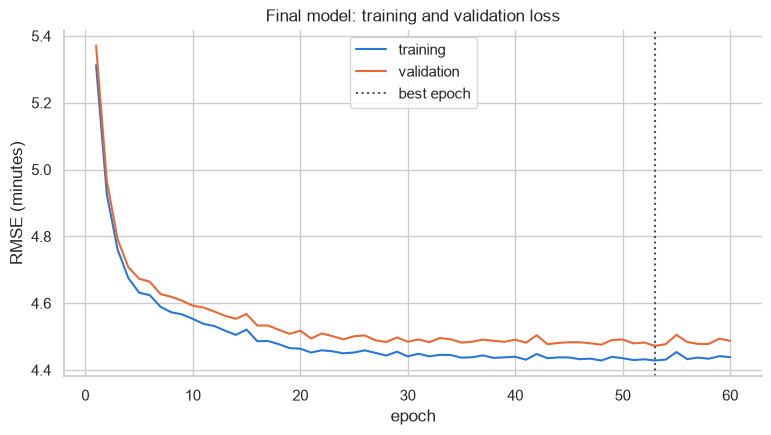

In [90]:
torch.manual_seed(0)
final = make_net(best_cfg["hidden"], best_cfg["act"], best_cfg["dropout"], best_cfg["bn"])
final_opt = make_optimizer(final.parameters(), best_cfg["optimizer"], best_cfg["lr"], best_cfg["wd"])

h_final = fit(final, final_opt, epochs=60, bs=best_cfg["bs"])
print("Best epoch:", h_final["best_epoch"] + 1, "| validation RMSE:", round(min(h_final["val"]), 3), "minutes")
show(h_final, "Final model: training and validation loss")

From the output above, the best configuration on the scoreboard is one hidden layer of 32 units with ReLU, Adam (learning rate 0.001), batch size 256 and no regularisation. That network has only 833 parameters. Trained for 60 epochs, its best epoch is 53 with a validation RMSE of 4.472 minutes. The training and validation curves lie on top of each other, so this small network does not overfit: it is limited by what the features can explain, not by memorisation.

## 5.5 Test Evaluation and Comparison with the Random Forest (Task 5.5)

Now, once, we use the test set. The network predicts in scaled units, so `y_scaler.inverse_transform` converts the predictions back to minutes. Both models are scored with exactly the same metrics on exactly the same test rows.

In [91]:
final.eval()
with torch.no_grad():
    nn_test_pred = y_scaler.inverse_transform(final(X_test_t).numpy()).ravel()

nn_test_res = regression_report(y_test, nn_test_pred)

comparison = pd.DataFrame({"Random Forest": rf_test_res, "Neural Network": nn_test_res})
comparison.round(3)

,Random Forest,Neural Network
MSE,22.015,19.735
RMSE,4.692,4.442
MAE,3.678,3.494
R2,0.744,0.770
MAPE_percent,8.135,7.713


The chart compares the two models on the three error metrics of the brief.

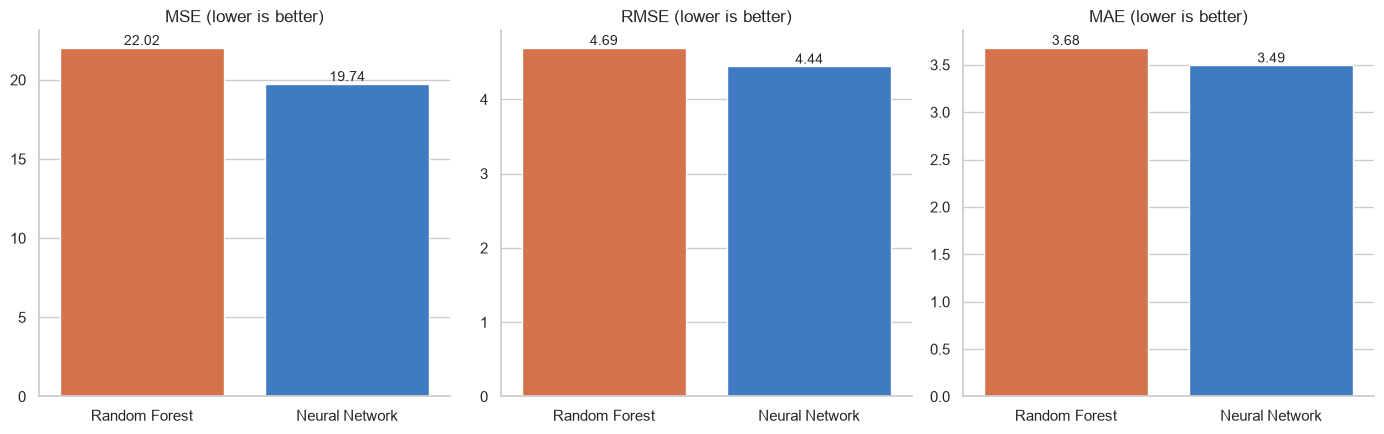

In [92]:
bars = comparison.loc[["MSE", "RMSE", "MAE"]].reset_index().melt(id_vars="index", var_name="model", value_name="value")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric in zip(axes, ["MSE", "RMSE", "MAE"]):
    sns.barplot(data=bars[bars["index"] == metric], x="model", y="value", hue="model",
                palette={"Random Forest": ORANGE, "Neural Network": BLUE}, legend=False, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=10)
    ax.bar_label(ax.containers[1], fmt="%.2f", fontsize=10)
    ax.set_title(f"{metric} (lower is better)")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Predicted against actual for each model, with the dashed diagonal as the perfect prediction.

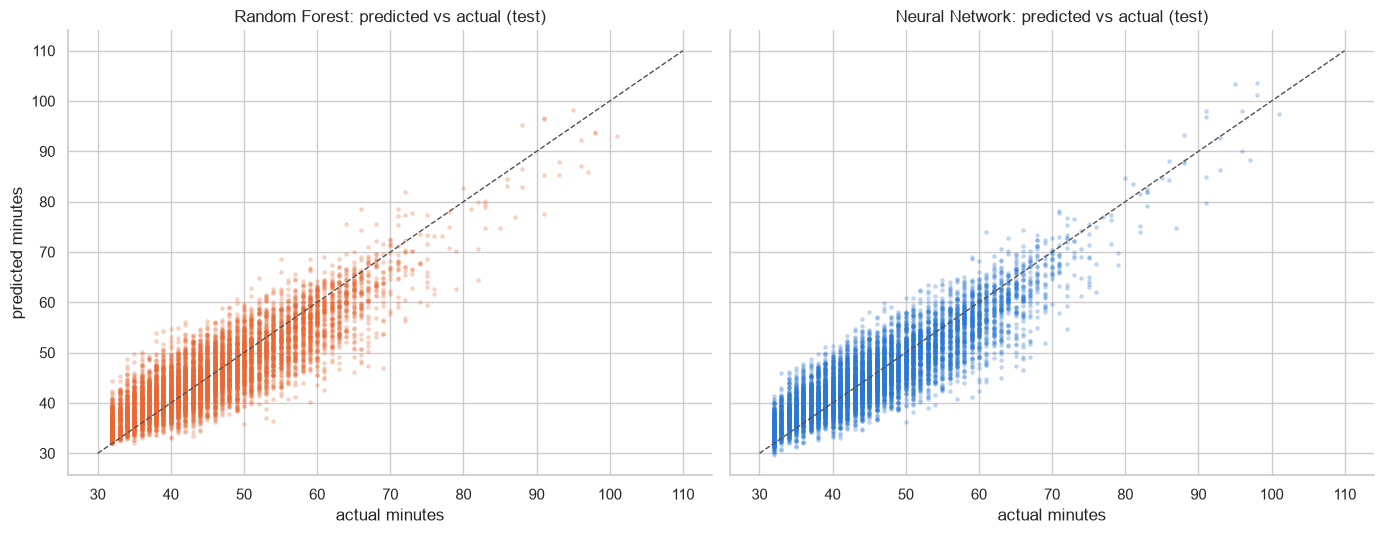

In [93]:
pred_frame = pd.DataFrame({"actual": y_test.values, "Random Forest": rf_test_pred, "Neural Network": nn_test_pred})
sample = pred_frame.sample(8000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, name, color in zip(axes, ["Random Forest", "Neural Network"], [ORANGE, BLUE]):
    sns.scatterplot(data=sample, x="actual", y=name, s=8, alpha=0.3, color=color, edgecolor=None, ax=ax)
    ax.plot([30, 110], [30, 110], color="#52514e", linestyle="--", linewidth=1)
    ax.set_title(f"{name}: predicted vs actual (test)")
    ax.set_xlabel("actual minutes")
    ax.set_ylabel("predicted minutes")
plt.tight_layout()
plt.show()

The distribution of the errors (actual minus predicted) for both models.

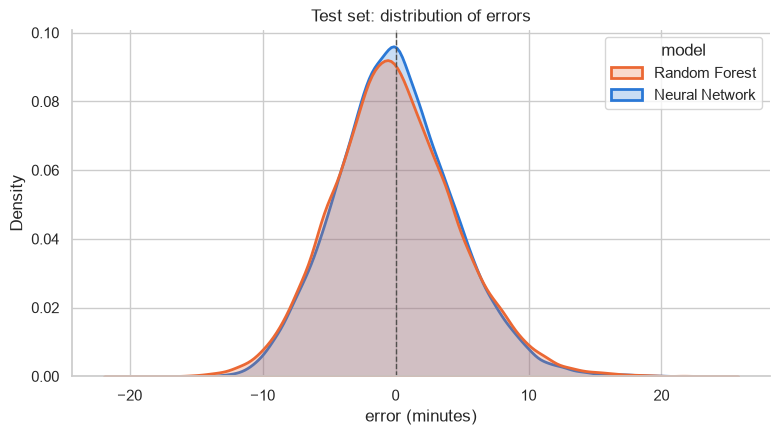

In [94]:
errors = pd.DataFrame({"Random Forest": y_test.values - rf_test_pred, "Neural Network": y_test.values - nn_test_pred})
errors_long = errors.melt(var_name="model", value_name="error (minutes)")

plt.figure(figsize=(9, 4.5))
sns.kdeplot(data=errors_long, x="error (minutes)", hue="model", palette={"Random Forest": ORANGE, "Neural Network": BLUE},
            fill=True, alpha=0.25, common_norm=False, linewidth=2)
plt.axvline(0, color="#52514e", linestyle="--", linewidth=1)
plt.title("Test set: distribution of errors")
plt.show()

From the output above, on the same 34,583 test rows the neural network is slightly better on every metric: RMSE 4.44 against 4.69 minutes, MAE 3.49 against 3.68, R² 0.770 against 0.744 and MAPE 7.7% against 8.1%. Its MSE is 19.7 against 22.0, about 10% lower.

The improvement is small in minutes (about 0.25 minutes of RMSE, or 5%), and both models make the same kind of mistake: they tend to predict too low for very slow deliveries (above about 70 minutes), as the predicted-against-actual charts show. Both explain about three quarters of the variation in delivery time. The forest fits its training rows far better than its test rows (RMSE 1.76 against 4.69), while the network's training and validation errors are almost equal. The next six tests ask whether this small lead is real.

### Is the Network Really Better? More Evidence

The table above shows that the network scores a little better. One test split cannot tell us whether that gap is real or luck, so we look at the question from six more sides, and we report each result as it comes out.

**Evidence 1: what the customer experiences.** An average error hides how often the promise is good enough. We count the share of test orders predicted within 3, 5 and 10 minutes of the real time, and how often the order arrives **more than 5 minutes later than promised** (the prediction was too low).

In [95]:
y_true = y_test.values
preds = {"Random Forest": rf_test_pred, "Neural Network": nn_test_pred}

def customer_view(pred):
    err = y_true - pred
    return {"within 3 min (%)": np.mean(np.abs(err) <= 3) * 100,
            "within 5 min (%)": np.mean(np.abs(err) <= 5) * 100,
            "within 10 min (%)": np.mean(np.abs(err) <= 10) * 100,
            "arrives > 5 min later than promised (%)": np.mean(err > 5) * 100}

pd.DataFrame({name: customer_view(p) for name, p in preds.items()}).round(2)

,Random Forest,Neural Network
within 3 min (%),49.72,51.51
within 5 min (%),72.39,74.67
within 10 min (%),96.53,97.62
arrives > 5 min later than promised (%),13.44,12.68


From the table, the network puts more orders inside every error band: 51.5% against 49.7% within 3 minutes, 74.7% against 72.4% within 5 minutes and 97.6% against 96.5% within 10 minutes. It also breaks its promise by more than 5 minutes less often (12.7% of orders against 13.4%). For a customer the gain is small but it points the same way: about two more orders in a hundred land within 5 minutes of the estimate.

**Evidence 2: is the gap bigger than the luck of the test sample?** We draw 1,000 new test sets by sampling the test rows with replacement (a *paired bootstrap*: both models are scored on exactly the same rows each time) and record how much lower the network's error is. If the 95% interval stays above zero, the network's lead is not a lucky draw of test rows.

In [96]:
rng = np.random.default_rng(42)
se_rf, se_nn = (y_true - rf_test_pred) ** 2, (y_true - nn_test_pred) ** 2
ae_rf, ae_nn = np.abs(y_true - rf_test_pred), np.abs(y_true - nn_test_pred)

rmse_gain, mae_gain = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_true), len(y_true))
    rmse_gain.append(np.sqrt(se_rf[i].mean()) - np.sqrt(se_nn[i].mean()))
    mae_gain.append(ae_rf[i].mean() - ae_nn[i].mean())

boot = pd.DataFrame({"RMSE": rmse_gain, "MAE": mae_gain})
summary_boot = pd.DataFrame({"mean gain (min)": boot.mean(),
                             "95% lower": boot.quantile(0.025),
                             "95% upper": boot.quantile(0.975),
                             "share of draws where the network wins (%)": (boot > 0).mean() * 100})
summary_boot.round(3)

,mean gain (min),95% lower,95% upper,share of draws where the network wins (%)
RMSE,0.250,0.229,0.271,100.0
MAE,0.185,0.168,0.203,100.0


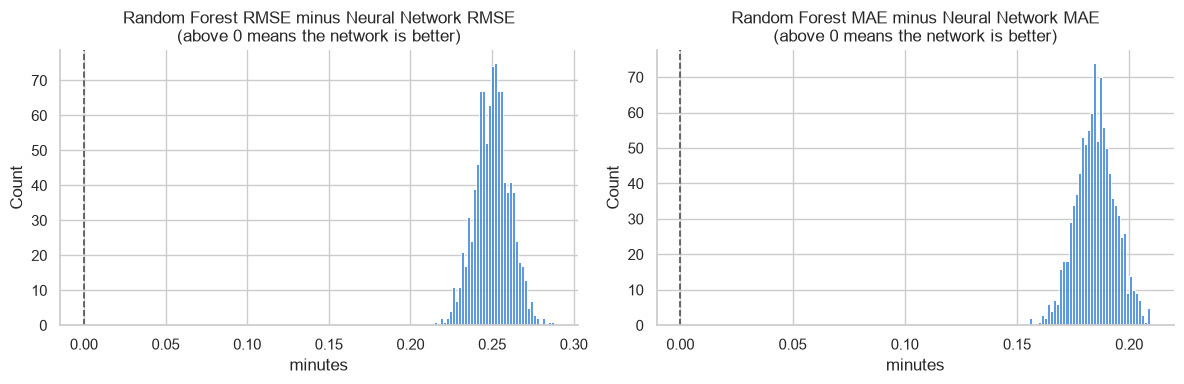

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["RMSE", "MAE"]):
    sns.histplot(boot[col], bins=40, color=BLUE, ax=ax)
    ax.axvline(0, color="#52514e", linestyle="--", linewidth=1.2)
    ax.set_title(f"Random Forest {col} minus Neural Network {col}\n(above 0 means the network is better)")
    ax.set_xlabel("minutes")
plt.tight_layout()
plt.show()

From the table and the chart, the network's RMSE is lower by 0.250 minutes on average, with a 95% interval of 0.229 to 0.271, and its MAE is lower by 0.185 minutes (0.168 to 0.203). In all 1,000 resampled test sets the network wins, and the whole interval lies above zero. So the lead is not the luck of which rows ended up in the test set. This test only covers the choice of test rows: it does not cover the choice of training rows or the random start, which the next test looks at.

**Evidence 3: is it just a lucky seed?** A neural network starts from random weights and a forest from random trees, so each result depends on the seed. We train the final network with 5 different seeds and the forest with 4 different seeds, keep the same split, and look at the spread of the test RMSE.

In [98]:
def final_net_rmse(seed):
    torch.manual_seed(seed)
    m = make_net(best_cfg["hidden"], best_cfg["act"], best_cfg["dropout"], best_cfg["bn"])
    fit(m, make_optimizer(m.parameters(), best_cfg["optimizer"], best_cfg["lr"], best_cfg["wd"]), epochs=60, bs=best_cfg["bs"])
    m.eval()
    with torch.no_grad():
        p = y_scaler.inverse_transform(m(X_test_t).numpy()).ravel()
    return regression_report(y_test, p)["RMSE"]

nn_rmse = [nn_test_res["RMSE"]] + [final_net_rmse(sd) for sd in [1, 2, 3, 4]]
rf_rmse = [rf_test_res["RMSE"]]
for sd in [1, 2, 3]:
    rf_sd = RandomForestRegressor(n_estimators=100, random_state=sd, n_jobs=-1).fit(X_train, y_train)
    rf_rmse.append(regression_report(y_test, rf_sd.predict(X_test))["RMSE"])

seed_table = pd.DataFrame({
    "runs": [len(rf_rmse), len(nn_rmse)],
    "mean test RMSE": [np.mean(rf_rmse), np.mean(nn_rmse)],
    "std between runs": [np.std(rf_rmse, ddof=1), np.std(nn_rmse, ddof=1)],
    "best run": [min(rf_rmse), min(nn_rmse)],
    "worst run": [max(rf_rmse), max(nn_rmse)],
}, index=["Random Forest", "Neural Network"])
seed_table.round(3)

,runs,mean test RMSE,std between runs,best run,worst run
Random Forest,4,4.693,0.004,4.688,4.697
Neural Network,5,4.445,0.007,4.434,4.454


From the table, the network's test RMSE moves very little between seeds (4.434 to 4.454, standard deviation 0.007) and so does the forest's (4.688 to 4.697, standard deviation 0.004). The **worst** of the 5 network runs (4.454) is better than the **best** of the 4 forest runs (4.688), by 0.23 minutes. So the difference is not a lucky seed. All runs use the same train and test split, so this still does not show how much a different split would change the numbers.

**Evidence 4: how much model is needed, and how fast is it?** A model that reaches the same accuracy with far fewer numbers is cheaper to store and faster to run when thousands of customers ask for an estimate at once. We compare the size, the time to predict the test orders, and the gap between training and test error (a large gap means the model memorised its training data).

In [99]:
import time

def predict_time(fn, repeats=5):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

def nn_predict():
    with torch.no_grad():
        return final(X_test_t)

with torch.no_grad():
    nn_train_pred = y_scaler.inverse_transform(final(X_train_t).numpy()).ravel()
nn_train_rmse = regression_report(y_train_nn, nn_train_pred)["RMSE"]

rf_nodes = sum(tree.tree_.node_count for tree in rf.estimators_)
nn_params = sum(p.numel() for p in final.parameters())

pd.DataFrame({
    "Random Forest": {"stored numbers": rf_nodes, "predict all test orders (seconds)": predict_time(lambda: rf.predict(X_test)),
                      "train RMSE": rf_train_res["RMSE"], "test RMSE": rf_test_res["RMSE"], "gap (test - train)": rf_test_res["RMSE"] - rf_train_res["RMSE"]},
    "Neural Network": {"stored numbers": nn_params, "predict all test orders (seconds)": predict_time(nn_predict),
                       "train RMSE": nn_train_rmse, "test RMSE": nn_test_res["RMSE"], "gap (test - train)": nn_test_res["RMSE"] - nn_train_rmse},
}).round(3)

,Random Forest,Neural Network
stored numbers,1.373706e+07,833.000
predict all test orders (seconds),1.620000e-01,0.001
train RMSE,1.763000e+00,4.428
test RMSE,4.692000e+00,4.442
gap (test - train),2.929000e+00,0.014


From the table, the network is far smaller and faster. The forest stores about 13.7 million tree nodes and the network 833 weights (these are different kinds of numbers, so read this as the order of magnitude, not as an exact ratio). Predicting all the test orders took about 0.17 seconds for the forest and about 0.001 seconds for the network on this computer (timings change a little from run to run). The forest's test error is 2.93 minutes above its training error, while the network's test error is only 0.014 minutes above its own, which shows how much more the forest memorises its training rows.

**Evidence 5: does the lead hold when the market is quiet and when it is busy?** A model that wins on average but fails when the market is busy would be a poor choice. We split the test orders into four equal groups by the number of orders waiting (`total_outstanding_orders`) and compare the RMSE of both models in each group.

In [100]:
busy = pd.qcut(X_test["total_outstanding_orders"], 4, labels=["quietest 25%", "quiet", "busy", "busiest 25%"])

rows = {}
for label in busy.cat.categories:
    mask = (busy == label).values
    rows[label] = {"orders": int(mask.sum()),
                   "Random Forest RMSE": np.sqrt(np.mean((y_true[mask] - rf_test_pred[mask]) ** 2)),
                   "Neural Network RMSE": np.sqrt(np.mean((y_true[mask] - nn_test_pred[mask]) ** 2))}
by_busy = pd.DataFrame(rows).T
by_busy["network better by (min)"] = by_busy["Random Forest RMSE"] - by_busy["Neural Network RMSE"]
by_busy.round(3)

,orders,Random Forest RMSE,Neural Network RMSE,network better by (min)
quietest 25%,8652.0,5.071,4.859,0.212
quiet,8806.0,4.970,4.756,0.213
busy,8587.0,4.690,4.405,0.285
busiest 25%,8538.0,3.940,3.629,0.311


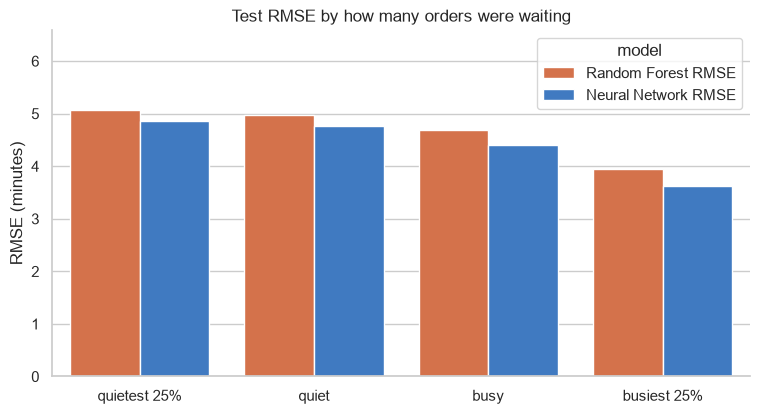

In [101]:
plot_busy = by_busy[["Random Forest RMSE", "Neural Network RMSE"]].reset_index().melt(id_vars="index", var_name="model", value_name="RMSE (minutes)")
plt.figure(figsize=(9, 4.5))
sns.barplot(data=plot_busy, x="index", y="RMSE (minutes)", hue="model", palette=[ORANGE, BLUE])
plt.ylim(0, plot_busy["RMSE (minutes)"].max() * 1.3)
plt.title("Test RMSE by how many orders were waiting")
plt.xlabel("")
plt.show()

From the table and the chart, the network is better in all four groups, by 0.21 minutes when the market is quiet, 0.29 when it is busy and 0.31 when it is busiest, so its lead is largest when accurate estimates matter most. Both models are least accurate when few orders are waiting (RMSE 4.9 to 5.1) and most accurate when the market is busiest (3.6 to 3.9).

**Evidence 6: is the forest being treated fairly?** Our Random Forest used the default settings and overfits (its training error is far below its test error). A fair comparison should give it a chance to do better. We try forests with at least 1, 5, 10 or 20 rows per leaf and with all or half of the features at each split, choose the best by the **validation** error (the same validation rows the network used), and only then score that forest on the test set once.

In [102]:
tune_rows = []
for leaf in [1, 5, 10, 20]:
    for feats in [1.0, 0.5]:
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=leaf, max_features=feats, random_state=42, n_jobs=-1).fit(X_train_nn, y_train_nn)
        tune_rows.append({"min_samples_leaf": leaf, "max_features": feats,
                          "validation RMSE": regression_report(y_val, m.predict(X_val))["RMSE"], "model": m})
tune = pd.DataFrame(tune_rows)
tuned_rf = tune.loc[tune["validation RMSE"].idxmin(), "model"]
tune.drop(columns="model").round(3)

,min_samples_leaf,max_features,validation RMSE
0,1,1.0,4.723
1,1,0.5,4.695
2,5,1.0,4.706
3,5,0.5,4.691
4,10,1.0,4.722
5,10,0.5,4.734
6,20,1.0,4.782
7,20,0.5,4.814


In [103]:
tuned_res = regression_report(y_test, tuned_rf.predict(X_test))
print("Chosen forest:", tuned_rf.get_params()["min_samples_leaf"], "rows per leaf, max_features =", tuned_rf.get_params()["max_features"])

pd.DataFrame({"Random Forest (default)": rf_test_res, "Random Forest (tuned)": tuned_res, "Neural Network": nn_test_res}).round(3)

Chosen forest: 5 rows per leaf, max_features = 0.5


,Random Forest (default),Random Forest (tuned),Neural Network
MSE,22.015,21.658,19.735
RMSE,4.692,4.654,4.442
MAE,3.678,3.665,3.494
R2,0.744,0.748,0.770
MAPE_percent,8.135,8.104,7.713


From the tables, the best forest on the validation rows has at least 5 rows per leaf and half of the features at each split (validation RMSE 4.691). Scored once on the test rows, it improves a little on the default forest (RMSE 4.654 against 4.692, MAE 3.665 against 3.678) but the network is still ahead (RMSE 4.442, MAE 3.494, R² 0.770 against 0.748). Together with Gradient Boosting (4.573, Section 4.4), this means the network's lead does not come from a poorly set-up baseline.

### Verdict: Which Model Is Stronger?

**The neural network is the stronger model here**, and the evidence is consistent:

| Evidence | Random Forest | Neural Network |
|:--|:--:|:--:|
| Test RMSE (minutes), lower is better | 4.692 | **4.442** |
| Test R², higher is better | 0.744 | **0.770** |
| Orders predicted within 5 minutes | 72.4% | **74.7%** |
| Paired bootstrap: network wins in | | **1,000 of 1,000 resamples** |
| Worst run over several seeds (RMSE) | 4.697 | **4.454** |
| Tuned forest (RMSE) / Gradient Boosting (RMSE) | 4.654 / 4.573 | **4.442** |
| Test error minus training error (minutes) | 2.929 | **0.014** |
| Stored numbers / time to predict the test orders | about 13.7 million / 0.17 s | **833 / 0.001 s** |
| Better in every market-busyness group | no | **yes (by 0.21 to 0.31 minutes)** |

**How strong is "stronger"?** The network wins on every test, but the gain is modest: about 0.25 minutes (15 seconds) of RMSE, or 5%. Both models explain about three quarters of the variation in delivery time, and both tend to under-predict very slow deliveries. The remaining error comes from information the features do not contain (traffic, weather, kitchen delays), so a bigger network cannot remove it. The network's real advantages are that it generalises cleanly (no overfitting), is far smaller and faster, and wins consistently, which matters when millions of estimates are served.

**What these tests do not show:** all results use one train and test split, and the driving-duration column was left out because the brief does not describe it.

### Saving the Model and Using It for a New Order

A model is only useful if it can be reused. We save the network's weights, the two scalers and the column order in the `models` folder, load the weights into a fresh network to check that it gives identical predictions, and then ask it for the delivery time of one new order.

In [104]:
import joblib, os

os.makedirs("models", exist_ok=True)
torch.save(final.state_dict(), "models/porter_delivery_nn.pt")
joblib.dump({"scaler": scaler, "y_scaler": y_scaler, "columns": list(X.columns), "hidden": best_cfg["hidden"]},
            "models/porter_delivery_preprocessing.joblib")

reloaded = make_net(best_cfg["hidden"], best_cfg["act"], best_cfg["dropout"], best_cfg["bn"])
reloaded.load_state_dict(torch.load("models/porter_delivery_nn.pt"))
reloaded.eval()
with torch.no_grad():
    same = torch.allclose(reloaded(X_test_t), final(X_test_t))
print("Saved files:", sorted(f for f in os.listdir("models") if f.startswith("porter_delivery")))
print("Reloaded network gives identical predictions:", same)

Saved files: ['porter_delivery_nn.pt', 'porter_delivery_preprocessing.joblib']
Reloaded network gives identical predictions: True


In [105]:
new_order = pd.DataFrame([{"market_id": 2, "order_protocol": 3, "total_items": 3, "subtotal": 2400, "num_distinct_items": 3,
                           "min_item_price": 400, "max_item_price": 1100, "total_onshift_dashers": 40, "total_busy_dashers": 35,
                           "total_outstanding_orders": 50, "hour": 20, "day_of_week": 5, "store_category_code": 4}])

new_X = pd.get_dummies(new_order, columns=["market_id", "order_protocol"], dtype=float).reindex(columns=X.columns, fill_value=0.0)
with torch.no_grad():
    estimate = y_scaler.inverse_transform(reloaded(torch.tensor(scaler.transform(new_X), dtype=torch.float32)).numpy())[0, 0]

print(f"Estimated delivery time for a new order (Saturday, hour 20, 3 items, subtotal 2400): {estimate:.0f} minutes")

Estimated delivery time for a new order (Saturday, hour 20, 3 items, subtotal 2400): 42 minutes


From the output above, the weights and the preprocessing objects were saved in the `models` folder, and a freshly built network that loaded the saved weights gives exactly the same predictions as the trained one (`True`). For the example order (Saturday, hour 20, 3 items, subtotal 2400, 40 partners on shift, 50 orders waiting) the model estimates 42 minutes, which sits inside the range of 40 to 50 minutes that we saw for similar hours and days in Section 3.6.

## 5.6 Why Neural Networks Perform Well on Large Datasets (Task 5.6, Brief Question 10)

> **Brief Question 10:** *Why does a neural network perform well on a large dataset?*


A neural network has many parameters (our baseline network has 11,521, and the final one has 833), and every parameter has to be estimated from data. With little data there are too few examples to pin them all down, so the network overfits or does not train well. With a lot of data, the same flexibility becomes an advantage: the network can learn complicated, smooth relationships and build its own features, and it keeps improving as more examples arrive. Many classical models flatten out earlier, because their capacity is limited by the features we hand them.

**What our own results show.** We have about 138,000 training rows, far more rows than parameters (even the largest network we tried, (256, 128, 64), has only 47,617), so the networks did not overfit badly: the baseline's training error was only about 0.2 minutes below its validation error. But the size experiment in Section 5.4 also shows that more capacity did **not** help: the smallest network (one layer of 32 units) did as well as the larger ones, and the regularisation experiment barely moved the validation error. For these 24 input columns the limit is the information in the features, not the size of the model. We did not train on growing slices of the data, so our experiment does not show that the network keeps improving with more rows. That statement is the general rule, not something we measured here.

## Section 5 Summary: Objective and How It Was Addressed

**Motto of this section:** *Build the network step by step, and judge it only on data it has never seen, against the baselines it has to beat.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 5.1 and Question 7:** scaling | **5.1**: `StandardScaler` on the features and the target, fitted on the training rows only; why a network needs it and a forest does not | 121,039 / 17,292 / 34,583 rows (train / validation / test) |
| **Task 5.2 and Question 9:** architecture and activations | **5.2**: ReLU hidden layers, one linear output neuron, Xavier initialisation | Baseline network 24 -> 128 -> 64 -> 1, 11,521 parameters |
| **Task 5.3 and Question 8:** loss and optimizer | **5.3**: `MSELoss` and Adam | Adam compared with SGD, momentum and RMSprop in 5.4 |
| **Task 5.4:** training, loss plots, overfitting, configurations | **5.4**: own training loop, early stopping on validation loss, six experiments (size, activation, optimiser, learning rate, batch size, regularisation), full scoreboard, final model | 28 runs within 4.482 to 4.540 validation RMSE; final model 32 hidden units, validation RMSE 4.472 |
| **Task 5.5:** same metrics, compare with the Random Forest | **5.5**: MSE, RMSE, MAE, R² and MAPE on the same test rows, charts, six further tests, verdict, saving the model | Neural network RMSE 4.44 vs forest 4.69 (tuned forest 4.65, gradient boosting 4.57); R² 0.770 vs 0.744 |
| **Task 5.6 and Question 10:** why networks do well on large data | **5.6** | Explained, and checked against our own results |

**Final result:** the neural network (test RMSE **4.44** minutes, MAE **3.49**) is stronger than the Random Forest baseline (RMSE 4.69, MAE 3.68), than a tuned forest (4.65) and than Gradient Boosting (4.57). Its lead is modest (about 0.25 minutes) but consistent across metrics, seeds, resampled test sets and market conditions. All models are far better than always predicting the average (about 9 minutes).

**Limits of this result:**
- One train and test split; the outlier rules were worked out before the split (Section 3.4).
- `estimated_store_to_consumer_driving_duration` was left out because the brief does not describe it (Section 2.4); its effect was not measured.
- Extra features such as traffic or weather are not in the data, so about a quarter of the variation stays unexplained.